<center><h1>Enriquez_Scott_HW6</h1></center>

Name: Scott Enriquez
<br>
GitHub Username: scottenriquez

## 1. Tree-Based Methods

Import packages

In [1]:
%pip install -q imbalanced-learn==0.14.2 matplotlib==3.11.2 numpy==2.5.4 'pandas[output-formatting]==3.1.0' scikit-learn==1.9.1 seaborn==0.13.2 scipy==1.18.1 statsmodels==0.15.0 xgboost==3.4.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imbalanced_pipeline
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [3]:
aps_failure_training_data = (
    pd.read_csv('Homework-6-Data/aps_failure_training_set.csv', skiprows=20, na_values='na'))
aps_failure_test_data = (
    pd.read_csv('Homework-6-Data/aps_failure_test_set.csv', skiprows=20, na_values='na'))
target_column = 'class'
feature_columns = aps_failure_training_data.columns.drop(target_column)
aps_failure_training_data[target_column] = (aps_failure_training_data[target_column] == 'pos').astype(int)
aps_failure_test_data[target_column] = (aps_failure_test_data[target_column] == 'pos').astype(int)
training_y_data = aps_failure_training_data[target_column]
test_x_data = aps_failure_test_data[feature_columns]
test_y_data = aps_failure_test_data[target_column]

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques include mean, median, and mode imputation, using KNN to impute values based on similar neighbors, iterative imputation, and tree-based imputation (e.g., random forest classifier). After researching the tradeoffs of various techniques, I chose `SimpleImputer` with the median value and a missing value indicator as my initial approach. Since all but one of the features have at least one missing value, I chose to preserve the missingness as a signal. Choosing median as the imputation statistic also reduces sensitivity to outliers.

In [4]:
simple_imputer = SimpleImputer(missing_values=np.nan, strategy='median', add_indicator=True).set_output(
    transform='pandas')
training_x_data_imputed = simple_imputer.fit_transform(aps_failure_training_data[feature_columns])

#### (ii) Calculate the coefficient of variation

In [5]:
coefficient_of_variation = (training_x_data_imputed.std() / training_x_data_imputed.mean()).sort_values(ascending=False)

#### (iii) Plot a correlation matrix

In [6]:
correlation_matrix = pd.concat([training_x_data_imputed[feature_columns], training_y_data], axis=1).corr()

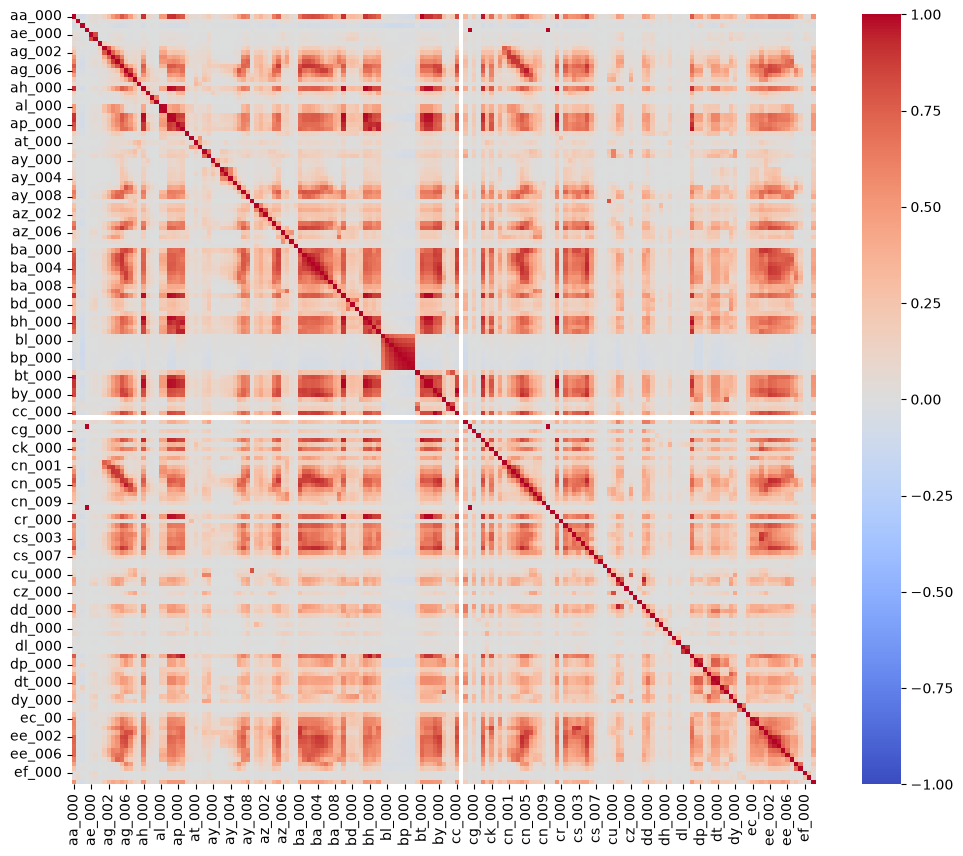

In [7]:
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.show()

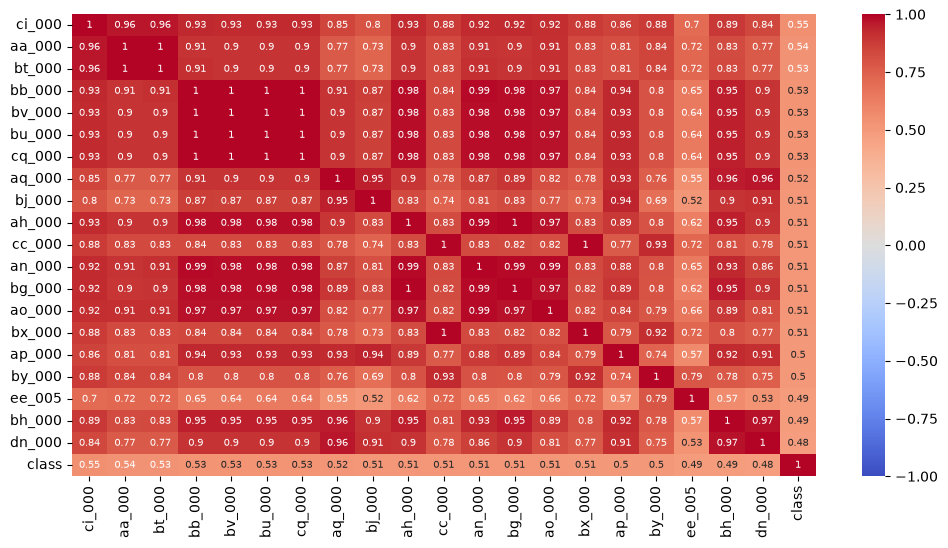

In [8]:
top_features_by_correlation = correlation_matrix[target_column].drop(target_column).abs().nlargest(
    20).index.tolist()
top_features_by_correlation.append(target_column)
plt.figure(figsize=(12, 6))
sns.heatmap(correlation_matrix.loc[top_features_by_correlation, top_features_by_correlation], cmap='coolwarm', vmin=-1,
            vmax=1, center=0, annot=True, annot_kws={'size': 7})
plt.show()

#### (iv) Make scatter plots and box plots

In [9]:
top_features_by_coefficient_of_variation = coefficient_of_variation.iloc[:math.floor(math.sqrt(170))].index.tolist()

In [10]:
highest_coefficient_of_variation_training_x_data = training_x_data_imputed[top_features_by_coefficient_of_variation]

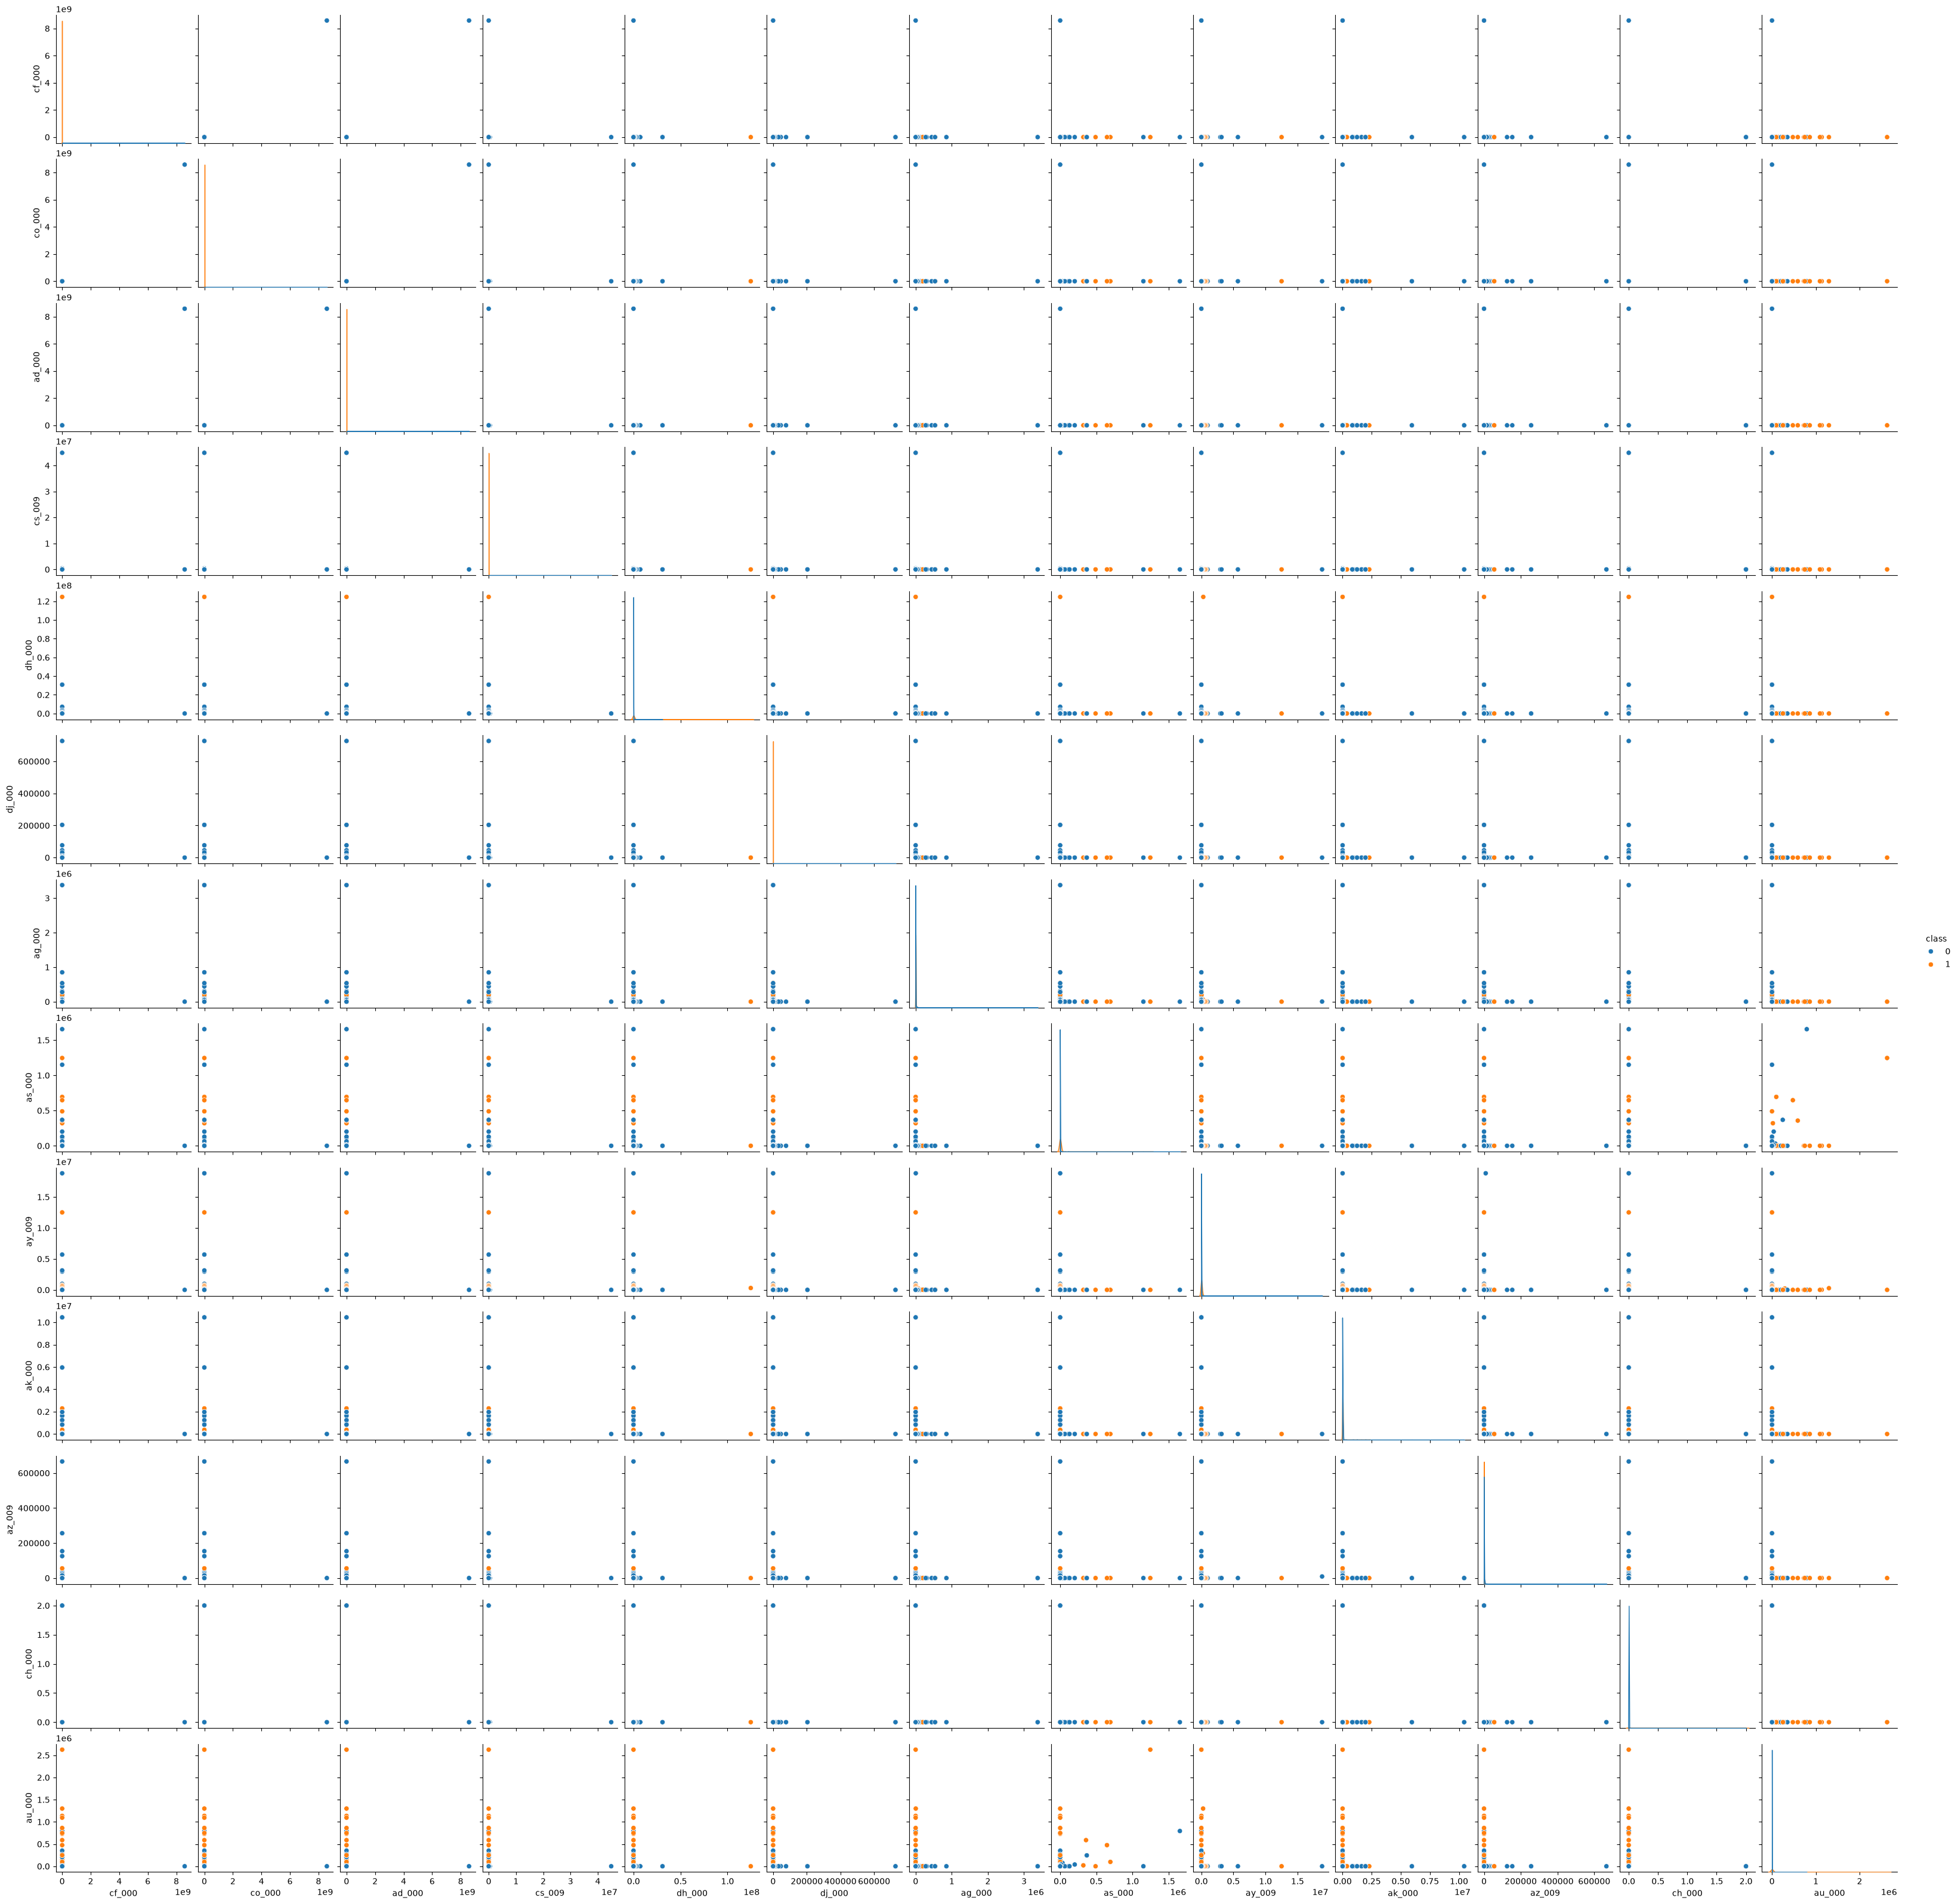

In [11]:
sns.pairplot(pd.concat([highest_coefficient_of_variation_training_x_data, training_y_data], axis=1), hue=target_column)
plt.show()

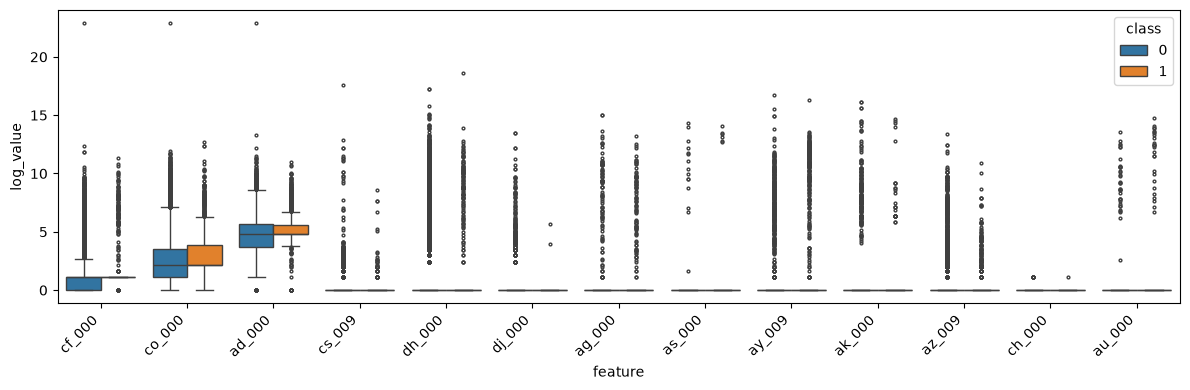

In [12]:
# use log to make the box plot more readable
box_plot_data = pd.concat([np.log1p(highest_coefficient_of_variation_training_x_data), training_y_data], axis=1).melt(
    id_vars=target_column, var_name='feature', value_name='log_value')
plt.figure(figsize=(12, 4))
sns.boxplot(data=box_plot_data, x='feature', y='log_value', hue=target_column, flierprops={'markersize': 2})
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

It's not possible to draw conclusions about the significance of these features from the plots alone. Features like `ag_000` appear to be non-zero when the class is positive per the pairplot, but this alone does not prove any significance.

#### (v) Is this data set imbalanced?

In [13]:
positive_class_training_count = (training_y_data == 1).sum()
positive_class_test_count = (test_y_data == 1).sum()
print(
    f'There are {positive_class_training_count} positive samples in {len(training_y_data)} total samples in the training set.')
print(
    f'There are {positive_class_test_count} positive samples in {len(test_y_data)} total samples in the test set.')

There are 1000 positive samples in 60000 total samples in the training set.
There are 375 positive samples in 16000 total samples in the test set.


The positive class represents 1.7% of the training set and 2.3% of the test set, therefore the data is highly imbalanced.

### (c) Train a random forest

In [14]:
def evaluate_classifier(report_name, classifier, training_x_data, training_y_data, test_x_data, test_y_data):
    figure, axes = plt.subplots(1, 3, figsize=(13, 4))
    for confusion_matrix_axis, dataset_name, x_data, y_data in [
        (axes[0], 'Training', training_x_data, training_y_data),
        (axes[1], 'Test', test_x_data, test_y_data),
    ]:
        predictions = classifier.predict(x_data)
        positive_class_probabilities = classifier.predict_proba(x_data)[:, 1]
        ConfusionMatrixDisplay.from_predictions(y_data, predictions, display_labels=['Negative', 'Positive'],
                                                ax=confusion_matrix_axis)
        confusion_matrix_axis.set_title(f'{dataset_name} Confusion Matrix')
        print(f'{report_name} ({dataset_name}) AUC: {roc_auc_score(y_data, positive_class_probabilities)}')
        print(f'{report_name} ({dataset_name}) Misclassification: {1 - accuracy_score(y_data, predictions)}')
        RocCurveDisplay.from_predictions(y_data, positive_class_probabilities, name=dataset_name, ax=axes[2])
    axes[2].set_title('ROC')
    figure.suptitle(report_name)
    figure.tight_layout()
    plt.show()

### (d) Research class imbalance in random forest

/opt/homebrew/Cellar/jupyterlab/4.6.6/libexec/lib/python3.15/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Balanced Random Forest Classifier (Training) AUC: 1.0
Balanced Random Forest Classifier (Training) Misclassification: 0.00013333333333331865
Balanced Random Forest Classifier (Test) AUC: 0.9947898026666666
Balanced Random Forest Classifier (Test) Misclassification: 0.008375000000000021


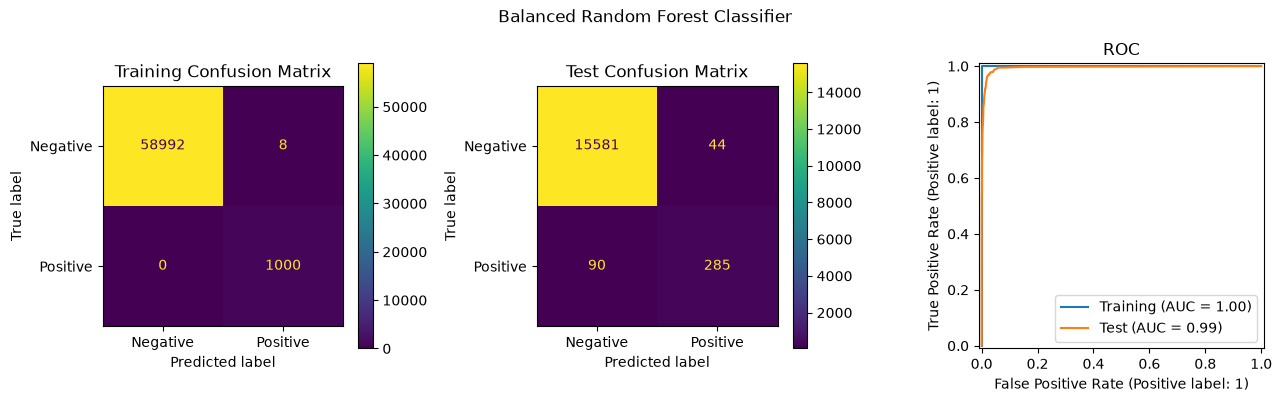

Out-of-Bag Error: 0.01980000000000004


In [15]:
balanced_random_forest_classifier = RandomForestClassifier(class_weight='balanced', oob_score=True, random_state=9999)
balanced_random_forest_classifier.fit(training_x_data_imputed, training_y_data)
evaluate_classifier('Balanced Random Forest Classifier', balanced_random_forest_classifier,
                    training_x_data_imputed, training_y_data, simple_imputer.transform(test_x_data), test_y_data)
print(f'Out-of-Bag Error: {1 - balanced_random_forest_classifier.oob_score_}')

Balanced Subsample Random Forest Classifier (Training) AUC: 1.0
Balanced Subsample Random Forest Classifier (Training) Misclassification: 0.0
Balanced Subsample Random Forest Classifier (Test) AUC: 0.9936593920000001
Balanced Subsample Random Forest Classifier (Test) Misclassification: 0.010812500000000003


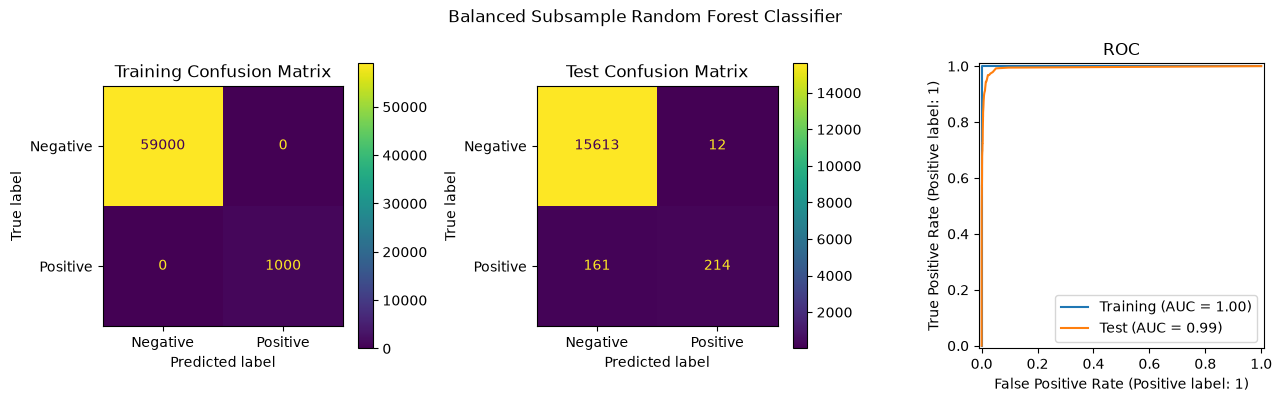

Out-of-Bag Error: 0.008050000000000002


In [16]:
balanced_subsample_random_forest_classifier = RandomForestClassifier(class_weight='balanced_subsample', oob_score=True,
                                                                     random_state=9999)
balanced_subsample_random_forest_classifier.fit(training_x_data_imputed, training_y_data)
evaluate_classifier('Balanced Subsample Random Forest Classifier', balanced_subsample_random_forest_classifier,
                    training_x_data_imputed, training_y_data, simple_imputer.transform(test_x_data), test_y_data)
print(f'Out-of-Bag Error: {1 - balanced_subsample_random_forest_classifier.oob_score_}')

I tested two mechanisms for dealing with class imbalance: `balanced` and `balanced_subsample` for the `class_weight`. `balanced` automatically adjusts weights inversely proportional to class frequencies in the input data. `balanced_subsample` is the same as `balanced` except that weights are computed based on the bootstrap sample for every tree grown.

While the test errors for the three models are similar (0.0077 for the default, 0.0084 for `balanced`, and 0.0108 for `balanced_subsample`), I would argue that the `balanced` model is actually the best based on its improvement of false negatives. Accuracy as a metric misses this distinction due to class imbalance.

### (e) XGBoost and Model Trees

In [17]:
imputed_binary_logistic_xgboost_pipeline = make_pipeline(
    SimpleImputer(missing_values=np.nan, strategy='median', add_indicator=True),
    XGBClassifier(objective='binary:logistic', booster='gbtree', random_state=9999),
)
grid_search_cross_validation = GridSearchCV(
    imputed_binary_logistic_xgboost_pipeline,
    param_grid={'xgbclassifier__reg_alpha': np.logspace(-4, 4, 25)},
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
)
grid_search_cross_validation.fit(aps_failure_training_data[feature_columns], training_y_data)
cross_validation_results = pd.DataFrame(grid_search_cross_validation.cv_results_)[
    ['param_xgbclassifier__reg_alpha', 'mean_test_score']]
cross_validation_results['cross_validation_error'] = 1 - cross_validation_results['mean_test_score']

In [18]:
display(cross_validation_results)
print(f'Best Alpha: {grid_search_cross_validation.best_params_["xgbclassifier__reg_alpha"]}')
print(f'Cross-Validation Error: {1 - grid_search_cross_validation.best_score_}')

,param_xgbclassifier__reg_alpha,mean_test_score,cross_validation_error
0,0.000100,0.993800,0.006200
1,0.000215,0.993850,0.006150
2,0.000464,0.993983,0.006017
3,0.001000,0.993900,0.006100
4,0.002154,0.994050,0.005950
5,0.004642,0.993933,0.006067
6,0.010000,0.993900,0.006100
7,0.021544,0.993783,0.006217
8,0.046416,0.993633,0.006367
9,0.100000,0.993950,0.006050


Best Alpha: 0.002154434690031882
Cross-Validation Error: 0.005950000000000011


XGBoost (Training) AUC: 1.0
XGBoost (Training) Misclassification: 1.666666666666483e-05
XGBoost (Test) AUC: 0.9899378346666667
XGBoost (Test) Misclassification: 0.0068749999999999645


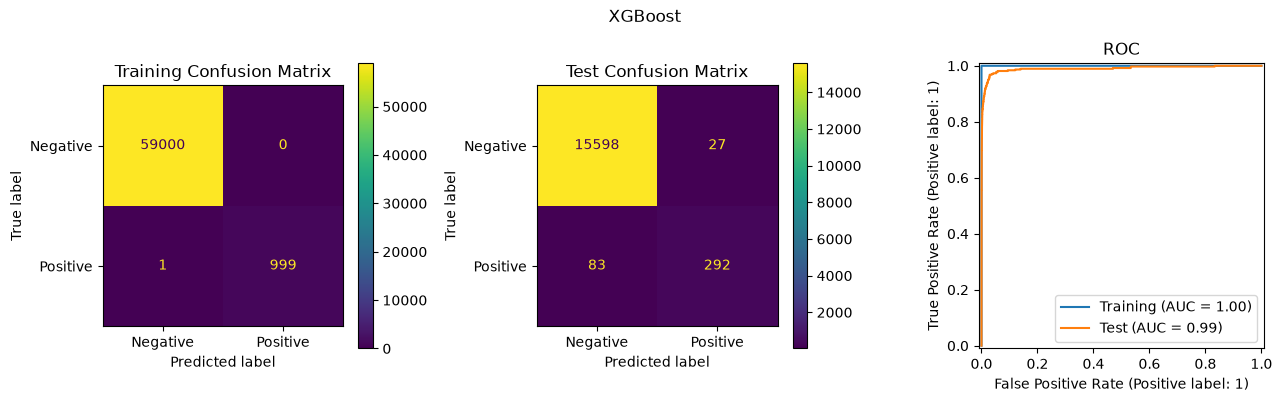

In [19]:
best_xgboost_model = grid_search_cross_validation.best_estimator_
evaluate_classifier('XGBoost', best_xgboost_model, aps_failure_training_data[feature_columns],
                    training_y_data, test_x_data, test_y_data)

### (f) Use SMOTE to pre-process your data

In [20]:
imputed_smote_binary_logistic_xgboost_pipeline = make_imbalanced_pipeline(
    SimpleImputer(missing_values=np.nan, strategy='median', add_indicator=True),
    SMOTE(random_state=9999),
    XGBClassifier(objective='binary:logistic', booster='gbtree', random_state=9999)
)
smote_grid_search_cross_validation = GridSearchCV(
    imputed_smote_binary_logistic_xgboost_pipeline,
    param_grid={'xgbclassifier__reg_alpha': np.logspace(-4, 4, 25)},
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
)
smote_grid_search_cross_validation.fit(aps_failure_training_data[feature_columns], training_y_data)
smote_cross_validation_results = pd.DataFrame(smote_grid_search_cross_validation.cv_results_)[
    ['param_xgbclassifier__reg_alpha', 'mean_test_score']]
smote_cross_validation_results['cross_validation_error'] = 1 - smote_cross_validation_results['mean_test_score']

In [21]:
display(smote_cross_validation_results)
print(f'Best Alpha: {smote_grid_search_cross_validation.best_params_["xgbclassifier__reg_alpha"]}')
print(f'Cross-Validation Error: {1 - smote_grid_search_cross_validation.best_score_}')

,param_xgbclassifier__reg_alpha,mean_test_score,cross_validation_error
0,0.000100,0.993500,0.006500
1,0.000215,0.993383,0.006617
2,0.000464,0.993533,0.006467
3,0.001000,0.993583,0.006417
4,0.002154,0.993567,0.006433
5,0.004642,0.993450,0.006550
6,0.010000,0.993467,0.006533
7,0.021544,0.993617,0.006383
8,0.046416,0.993217,0.006783
9,0.100000,0.993317,0.006683


Best Alpha: 0.46415888336127775
Cross-Validation Error: 0.006366666666666632


XGBoost with SMOTE (Training) AUC: 0.9999894830508474
XGBoost with SMOTE (Training) Misclassification: 1.666666666666483e-05
XGBoost with SMOTE (Test) AUC: 0.9936547840000001
XGBoost with SMOTE (Test) Misclassification: 0.006624999999999992


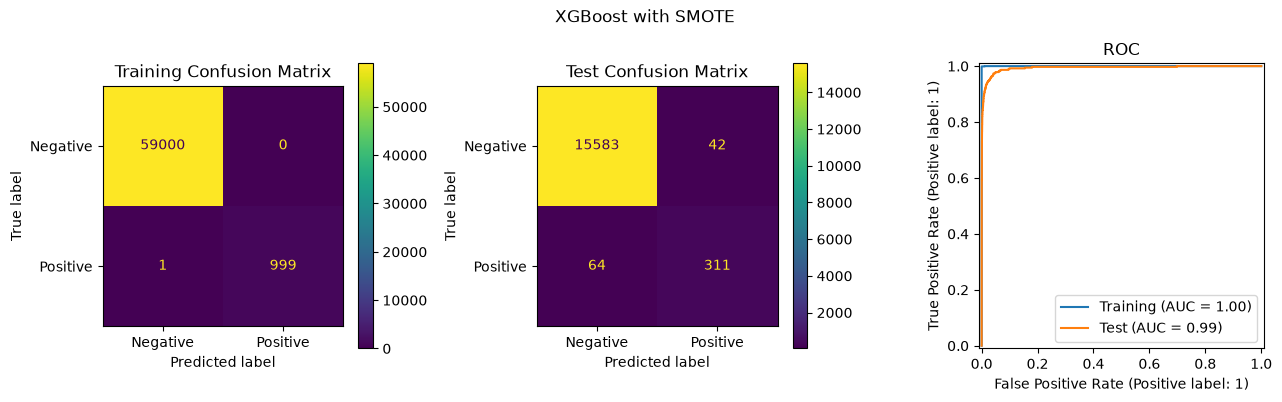

In [22]:
best_smote_xgboost_model = smote_grid_search_cross_validation.best_estimator_
evaluate_classifier('XGBoost with SMOTE', best_smote_xgboost_model, aps_failure_training_data[feature_columns],
                    training_y_data, test_x_data, test_y_data)

The overall test error did not change much between the non-SMOTE and SMOTE models (0.0068 versus 0.0066), but SMOTE did improve false negatives at the expense of false positives.

## 2. ISLR 6.6.3

(a) The answer is (iv). As `s` increases, there are less strict limits on the model's coefficients, so the training RSS steadily decreases. Any set of coefficients that fits a lower `s` is also in the set of coefficients that allows a higher `s`.


(b) The answer is (ii). As `s` increases initially, the model generalizes and learns the relationships between the coefficient and target, causing the test RSS to decreases. However, the model starts to overfit the training data at certain point, causing the test RSS to increase.

(c) The answer is (iii). As `s` increases, the coefficients can take on larger values that fit the training data better. As that fit happens, variance steadily increases since a different sample would fit the data much differently.

(d) The answer is (iv). as `s` increases, there are less strict requirements for the model. As such, the bias decreases with said flexibility.

(e) The answer is (v). Regardless of `s`, the irreducible error is a product of the noise in the data itself. Coefficent selection has no impact on this.

## 3. ISLR 6.6.5

(a) Start with the general formula:

$$\sum_{i=1}^{n}\left(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\right)^2 + \lambda\sum_{j=1}^{p}\beta_j^2$$

Since $n=2$ and $p=2$, this means that we only have two samples and two features. $\beta_0=0$, so we can drop that from the formula. 

$$\sum_{i=1}^{2}\left(y_i - \sum_{j=1}^{2}\beta_j x_{ij}\right)^2 + \lambda\sum_{j=1}^{2}\beta_j^2$$

Next, expand the terms.

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$

Since $x_{11} = x_{12}$ and $x_{21} = x_{22}$, substitute the terms in the formula. 

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{11})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{21})^2 + \lambda(\beta_1^2 + \beta_2^2)$$

Finding $min_{\beta_1, \beta_2}$ for this formula is the ridge optimization problem.

(b)

(c) Start with the general formula: $$\sum_{i=1}^{n}\left(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\right)^2 + \lambda\sum_{j=1}^{p}|\beta_j|$$

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|)$$

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{11})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{21})^2 + \lambda(|\beta_1| + |\beta_2|)$$

Finding $min_{\beta_1, \beta_2}$ for this formula is the Lasso optimization problem.

(d)

## 4. ISLR 8.4.5

Method one (majority polling) produces a prediction of `Red` since 6/10 estimates pick `Red` (i.e., their probability is greater than 0.5). Method two (average probability) involves summing the probabilities (4.5 total) and dividing by the number of estimates (10). At 0.45, the prediction is `Green` since it's less than 0.5.

## 5. ISLR 9.7.3

In [23]:
data = pd.DataFrame({
    'x1': [3, 2, 4, 1, 2, 4, 4],
    'x2': [4, 2, 4, 4, 1, 3, 1],
    'y': ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue'],
})

(a)

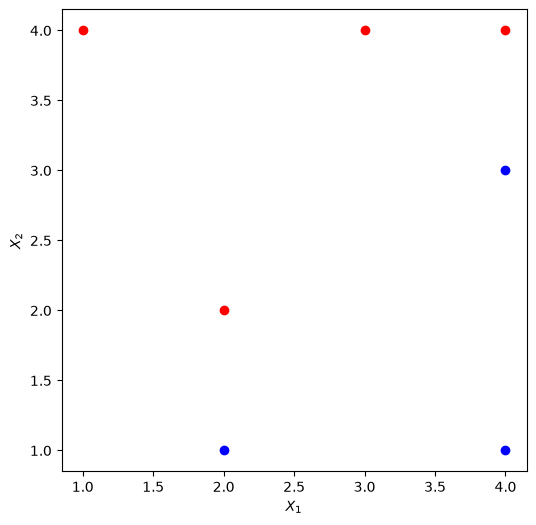

In [24]:
_, axis = plt.subplots(figsize=(6, 6))
for classification in data['y'].unique():
    class_data = data[data['y'] == classification]
    axis.scatter(class_data['x1'], class_data['x2'], color=classification.lower(), label=classification)
axis.set_xlabel('$X_1$')
axis.set_ylabel('$X_2$')
plt.show()

(b)

The ideal hyperplane has points (2, 1.5) and (4, 3.5), which are midpoints between the red and blue support vectors. The red support vectors are (2, 2) and (4, 4). The blue support vectors are (2, 1) and (4, 3). The slope for the maximal margin hyperplane is 1 based on the midpoints: `(3.5 - 1.5) / (4 - 2) = 1`. The intercept is then -0.5. The final formula is $0.5 - X_1 + X_2 = 0$.

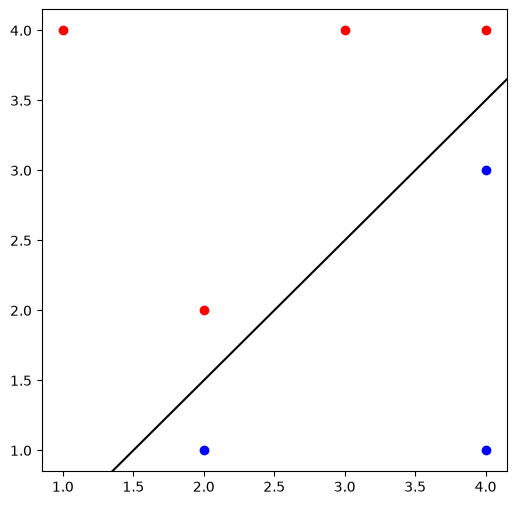

In [25]:
_, axis = plt.subplots(figsize=(6, 6))
for classification in data['y'].unique():
    class_data = data[data['y'] == classification]
    axis.scatter(class_data['x1'], class_data['x2'], color=classification.lower(), label=classification)
axis.axline((2, 1.5), slope=1, color='black')
plt.show()

(c) Classify to red if $0.5 - X_1 + X_2 > 0$. Classify to blue otherwise. $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

(d)

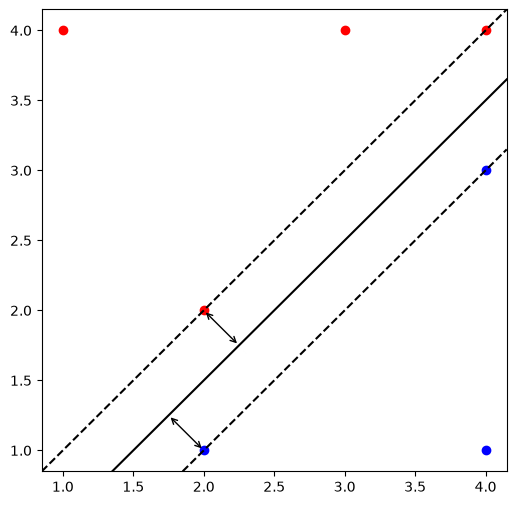

In [26]:
_, axis = plt.subplots(figsize=(6, 6))
for classification in data['y'].unique():
    class_data = data[data['y'] == classification]
    axis.scatter(class_data['x1'], class_data['x2'], color=classification.lower(), label=classification)
axis.axline((2, 1.5), slope=1, color='black', label='Hyperplane')
axis.axline((2, 2), slope=1, color='black', linestyle='--', label='Margin')
axis.axline((2, 1), slope=1, color='black', linestyle='--')
axis.annotate('', xy=(2.25, 1.75), xytext=(2, 2), arrowprops={'arrowstyle': '<->'})
axis.annotate('', xy=(1.75, 1.25), xytext=(2, 1), arrowprops={'arrowstyle': '<->'})
plt.show()

(e) The red support vectors are (2, 2) and (4, 4). The blue support vectors are (2, 1) and (4, 3).

(f) Movement of the seventh observation at (4, 1) would not impact the maximal margin hyperplane since this point is not part of either the red or blue support vectors. It's also far away from the support vectors, so there's no risk that it might cross the boundary.

(g) $0.25 - X_1 + X_2 = 0$

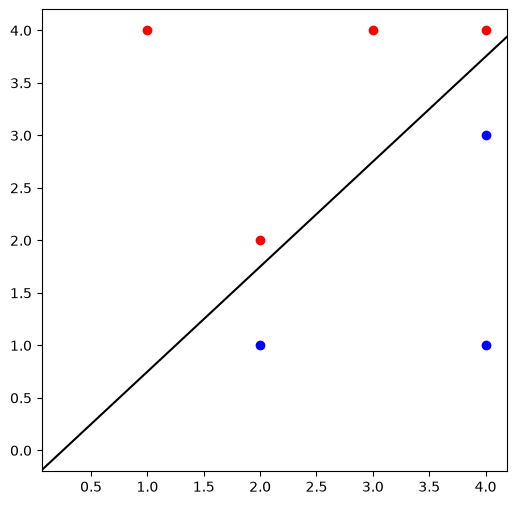

In [27]:
_, axis = plt.subplots(figsize=(6, 6))
for classification in data['y'].unique():
    class_data = data[data['y'] == classification]
    axis.scatter(class_data['x1'], class_data['x2'], color=classification.lower(), label=classification)
axis.axline((0.25, 0), slope=1, color='black')
plt.show()

(h) Adding a blue point at (4, 5) makes it impossible to separate.

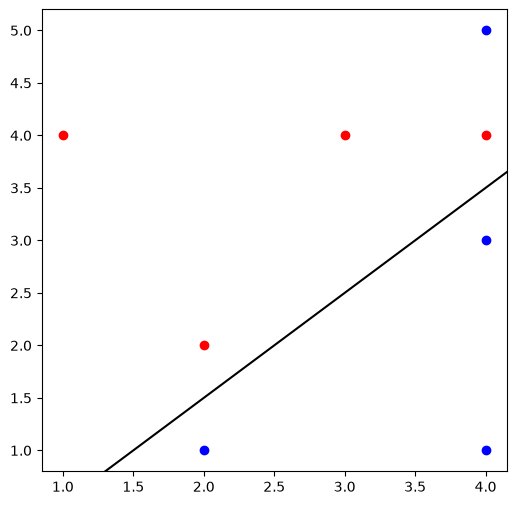

In [28]:
data = pd.DataFrame({
    'x1': [3, 2, 4, 1, 2, 4, 4, 4],
    'x2': [4, 2, 4, 4, 1, 3, 1, 5],
    'y': ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue', 'Blue'],
})
_, axis = plt.subplots(figsize=(6, 6))
for classification in data['y'].unique():
    class_data = data[data['y'] == classification]
    axis.scatter(class_data['x1'], class_data['x2'], color=classification.lower(), label=classification)
axis.axline((2, 1.5), slope=1, color='black')
plt.show()